✅ ดึงข้อมูลและประเมินผลทั้ง 3 โมเดลเรียบร้อย:


,Model,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1),True Positives (Caught Target),False Positives (Wasted Calls)
0,Random Forest,0.823,0.340,0.558,0.423,560,1085
1,XGBoost,0.835,0.368,0.583,0.451,585,1004
2,Logistic Regression,0.769,0.280,0.629,0.387,632,1626


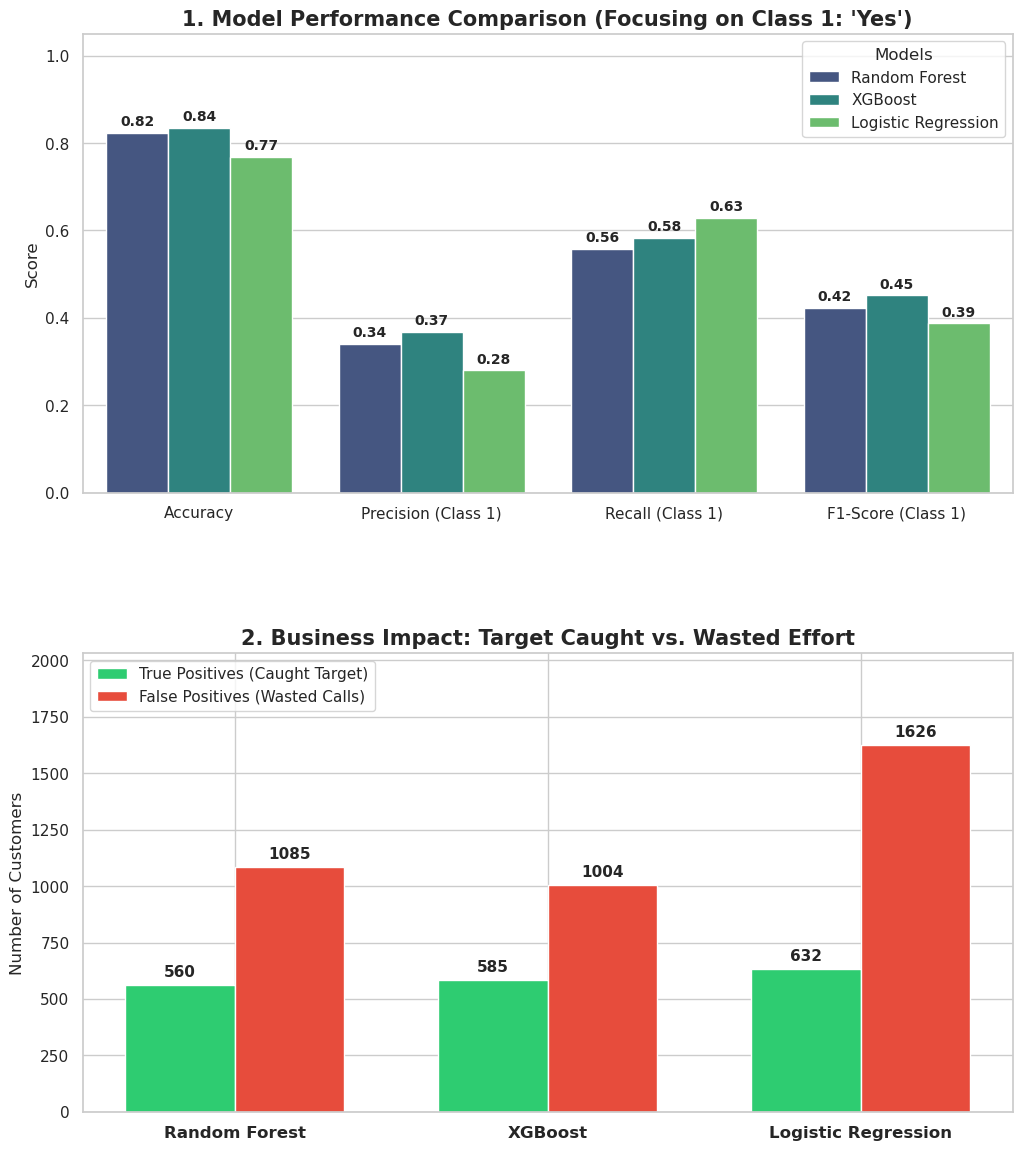

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# ==========================================
# 1. โหลดและเตรียมข้อมูล (ให้สเกลตรงกับตอนเทรน 100%)
# ==========================================
train_df = pd.read_csv("../cleaned_data/train_data.csv")
test_df = pd.read_csv("../cleaned_data/test_data.csv")

def engineer_features(df):
    df = df.copy()
    df['is_senior'] = (df['age'] >= 60).astype(int)
    df['has_free_cash'] = ((df['balance'] > 0) & (df['housing'] == 'no') & (df['loan'] == 'no')).astype(int)
    df['total_contacts'] = df['campaign'] + df['previous']
    df['is_balance_negative'] = (df['balance'] < 0).astype(int)
    return df

train_fe = engineer_features(train_df)
test_fe = engineer_features(test_df)

X_train = train_fe.drop(columns=['y'])
X_test = test_fe.drop(columns=['y'])
y_test = test_fe['y']

# One-Hot Encoding & Align คอลัมน์
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, drop_first=True)
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Fit Scaler บน Train และ Transform บน Test (ป้องกัน Data Leakage)
scaler = StandardScaler()
scaler.fit(X_train_encoded)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_encoded), columns=X_test_encoded.columns)

# โหลด X_test เฉพาะของ Random Forest (22 ฟีเจอร์)
X_test_rf = pd.read_csv("../cleaned_data/X_test_selected_rf.csv")

# ==========================================
# 2. โหลดโมเดลทั้ง 3 ตัวจากโฟลเดอร์ models
# ==========================================
rf_model = joblib.load("../models/rf_model.pkl")
xgb_model = joblib.load("../models/xgb_model.pkl")
lr_model = joblib.load("../models/lr_model.pkl")

# ==========================================
# 3. ฟังก์ชันประเมินผลและดึงค่าอัตโนมัติ
# ==========================================
def evaluate_model(model, X, y, threshold=0.50):
    if hasattr(model, "predict_proba"):
        y_probs = model.predict_proba(X)[:, 1]
        y_pred = (y_probs >= threshold).astype(int)
    else:
        y_pred = model.predict(X)
        
    acc = accuracy_score(y, y_pred)
    prec = precision_score(y, y_pred)
    rec = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    
    cm = confusion_matrix(y, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    return acc, prec, rec, f1, tp, fp

# ==========================================
# 4. รวบรวมผลลัพธ์จากทุกโมเดล
# ==========================================
results = []

# 1. Random Forest (ใช้ Threshold 0.48 ตามที่จูนไว้ในไฟล์)
rf_metrics = evaluate_model(rf_model, X_test_rf, y_test, threshold=0.48)
results.append(['Random Forest'] + list(rf_metrics))

# 2. XGBoost (ใช้ Threshold 0.50)
xgb_metrics = evaluate_model(xgb_model, X_test_scaled, y_test, threshold=0.50)
results.append(['XGBoost'] + list(xgb_metrics))

# 3. Logistic Regression (ใช้ Threshold 0.50)
lr_metrics = evaluate_model(lr_model, X_test_scaled, y_test, threshold=0.50)
results.append(['Logistic Regression'] + list(lr_metrics))

columns = [
    'Model', 'Accuracy', 'Precision (Class 1)', 'Recall (Class 1)', 
    'F1-Score (Class 1)', 'True Positives (Caught Target)', 'False Positives (Wasted Calls)'
]

df_results = pd.DataFrame(results, columns=columns)

# เซฟตารางสรุปผลเก็บไว้เป็น CSV เผื่อนำไปใช้ต่อใน Report
df_results.to_csv("../models/model_comparison_summary.csv", index=False)

print("✅ ดึงข้อมูลและประเมินผลทั้ง 3 โมเดลเรียบร้อย:")
display(df_results.round(3))

# ==========================================
# 5. สร้างกราฟ Visualization เปรียบเทียบ (ฉบับปรับไม่ให้ Legend บังตัวเลข)
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(12, 14))
fig.subplots_adjust(hspace=0.35)

# กราฟ 1: เปรียบเทียบ Performance Metrics
df_melted = df_results.melt(
    id_vars='Model', 
    value_vars=['Accuracy', 'Precision (Class 1)', 'Recall (Class 1)', 'F1-Score (Class 1)'],
    var_name='Metric', 
    value_name='Score'
)

sns.barplot(data=df_melted, x='Metric', y='Score', hue='Model', ax=axes[0], palette='viridis')
axes[0].set_title("1. Model Performance Comparison (Focusing on Class 1: 'Yes')", fontsize=15, fontweight='bold')
axes[0].set_ylim(0, 1.05) # เพิ่มเพดานเผื่อด้านบน
axes[0].set_ylabel("Score")
axes[0].set_xlabel("")
axes[0].legend(title="Models", loc='upper right', frameon=True, facecolor='white')

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3, fontsize=10, fontweight='bold')

# กราฟ 2: เปรียบเทียบ Business Impact (TP vs FP)
x = np.arange(len(df_results['Model']))
width = 0.35

bar1 = axes[1].bar(x - width/2, df_results['True Positives (Caught Target)'], width, label='True Positives (Caught Target)', color='#2ecc71')
bar2 = axes[1].bar(x + width/2, df_results['False Positives (Wasted Calls)'], width, label='False Positives (Wasted Calls)', color='#e74c3c')

axes[1].set_title("2. Business Impact: Target Caught vs. Wasted Effort", fontsize=15, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_results['Model'], fontsize=12, fontweight='bold')
axes[1].set_ylabel("Number of Customers")

# ขยายเพดานแกน Y ให้สูงขึ้นเป็น 1.25 เท่า เพื่อให้มีพื้นที่ด้านบนเหลือเฟือ
axes[1].set_ylim(0, max(df_results['False Positives (Wasted Calls)']) * 1.25)

# ย้ายกล่อง Legend มาไว้ฝั่งซ้ายบน (loc='upper left') จะได้ไม่ชนกับแท่งขวาสุด
axes[1].legend(loc='upper left', fontsize=11, frameon=True, facecolor='white')

axes[1].bar_label(bar1, fmt='%d', padding=4, fontsize=11, fontweight='bold')
axes[1].bar_label(bar2, fmt='%d', padding=4, fontsize=11, fontweight='bold')

plt.show()